# Project 21: Flight Delay Prediction and Rescheduling
## Task 5 — PCA Dimensionality Reduction & Final Benchmark Synthesis

**Author:** Ajeesh Amreet (Student ID: `2401010048`)  
**Role:** Member 5 (Dimensionality Reduction, Unified Evaluation & Simulation)  
**Phase:** Applied Machine Learning (AML) Phase 1  

---

### Module Overview
This notebook delivers the unsupervised compression and final evaluation synthesis for Phase 1:
1. **Part A (Principal Component Analysis - Topic 11):** Eigendecomposition of 31 standardized features, scree plot analysis, and proving that 15 components capture **96.72% variance** while preserving full classification ROC-AUC.
2. **Part B (Unified Benchmark & Synthesis):** Comprehensive evaluation across all partitions (Train, Val, Frozen Test), confusion matrices, and model scorecard comparing regression vs. classification paradigms.


In [1]:
# Step 1: Environment Setup and Library Imports
import os
import sys
from pathlib import Path
import warnings

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
)
from sklearn.preprocessing import StandardScaler

from src.classification import ALL_CLASSIFICATION_FEATURES, build_classification_pipeline
from src.config import FIGURES_DIR, PROCESSED_DATA_DIR, RANDOM_STATE
from src.features import FEATURE_COLUMNS_CATEGORICAL, FEATURE_COLUMNS_NUMERIC

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.dpi": 150})

PCA_FIGS_DIR = FIGURES_DIR / "pca"
PCA_FIGS_DIR.mkdir(parents=True, exist_ok=True)

print("✓ Environment initialized successfully.")
print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Numeric Features for PCA: {len(FEATURE_COLUMNS_NUMERIC)}")
print(f"✓ Categorical Features for Pipeline: {len(FEATURE_COLUMNS_CATEGORICAL)}")

✓ Environment initialized successfully.
✓ Project Root: /Users/ajeeshamreet/Downloads/aml
✓ Numeric Features for PCA: 31
✓ Categorical Features for Pipeline: 5


## 1. Mathematical Foundations of Principal Component Analysis

### 1.1 Mean Centering & Standardization
Let $X \in \mathbb{R}^{m \times d}$ denote the pre-departure numerical feature matrix with $m$ flight records and $d = 31$ features. Because flight variables possess vastly differing physical units (e.g., flight distance in thousands of miles vs. cyclical coordinates bounded in $[-1, 1]$), unscaled PCA would be completely dominated by variables with the largest absolute scales.

We standardize each feature $j \in \{1, \dots, d\}$ strictly using the **training partition sample mean** $\mu_j$ and **sample standard deviation** $\sigma_j$:

$$z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}$$

Yielding the standardized data matrix $Z \in \mathbb{R}^{m \times d}$, where each column satisfies $\mathbb{E}[z_j] = 0$ and $\text{Var}(z_j) = 1$.

### 1.2 Covariance Matrix & Spectral Decomposition
The sample covariance matrix of the standardized training data is:

$$\Sigma = \frac{1}{m - 1} Z^T Z \in \mathbb{R}^{d \times d}$$

Since $\Sigma$ is symmetric positive semi-definite, by the Spectral Theorem there exists an orthogonal matrix of eigenvectors $V = [v_1, v_2, \dots, v_d] \in \mathbb{R}^{d \times d}$ and a diagonal matrix of eigenvalues $\Lambda = \text{diag}(\lambda_1, \lambda_2, \dots, \lambda_d)$ with $\lambda_1 \ge \lambda_2 \ge \dots \ge \lambda_d \ge 0$ such that:

$$\Sigma = V \Lambda V^T \quad \Longleftrightarrow \quad \Sigma v_j = \lambda_j v_j$$

Each eigenvalue $\lambda_j$ equals the variance of the data projected onto principal axis $v_j$.

### 1.3 Singular Value Decomposition (SVD)
In practice, scikit-learn computes PCA directly via the Singular Value Decomposition (SVD) of $Z$:

$$Z = U S V^T$$

Where:
- $U \in \mathbb{R}^{m \times d}$ contains left singular vectors ($U^T U = I_d$).
- $S = \text{diag}(s_1, \dots, s_d)$ contains singular values, where $\lambda_j = \frac{s_j^2}{m - 1}$.
- $V \in \mathbb{R}^{d \times d}$ contains right singular vectors (principal component loading directions).

### 1.4 Projection & Explained Variance Ratio
To project $Z$ onto a reduced $k$-dimensional subspace ($k < d$):

$$Z_{\text{pca}} = Z V_k \in \mathbb{R}^{m \times k}$$

The individual and cumulative explained variance ratios are:

$$\text{EVR}_j = \frac{\lambda_j}{\sum_{i=1}^d \lambda_i}, \qquad \text{Cumulative EVR}(k) = \frac{\sum_{j=1}^k \lambda_j}{\sum_{i=1}^d \lambda_i}$$

In [2]:
# Step 2: Ingest Feature Dataset and Enforce Chronological Partitions
features_path = PROCESSED_DATA_DIR / "flights_features.csv"
if not features_path.exists():
    raise FileNotFoundError(f"Feature dataset not found at: {features_path}")

df = pd.read_csv(features_path)
print(f"Loaded dataset: {df.shape[0]:,} rows, {df.shape[1]} columns.")

# Chronological partition extraction
train_df = df[df["SPLIT_SET"] == "train"].copy()
val_df   = df[df["SPLIT_SET"] == "val"].copy()
test_df  = df[df["SPLIT_SET"] == "test"].copy()

print(f"  - Training Set   : {len(train_df):,} flights ({train_df['FLIGHT_DATE'].min()} to {train_df['FLIGHT_DATE'].max()})")
print(f"  - Validation Set : {len(val_df):,} flights ({val_df['FLIGHT_DATE'].min()} to {val_df['FLIGHT_DATE'].max()})")
print(f"  - Held-Out Test  : {len(test_df):,} flights ({test_df['FLIGHT_DATE'].min()} to {test_df['FLIGHT_DATE'].max()})")

# Target extraction
y_train = train_df["DELAYED"].values.astype(int)
y_val   = val_df["DELAYED"].values.astype(int)
y_test  = test_df["DELAYED"].values.astype(int)

# Verify zero missing values in numerical feature candidates
num_cols = FEATURE_COLUMNS_NUMERIC
print(f"\nVerifying {len(num_cols)} numerical features for PCA:")
print(f"Null count in numerical features: {train_df[num_cols].isnull().sum().sum()}")

Loaded dataset: 24,522 rows, 46 columns.
  - Training Set   : 16,366 flights (2015-01-01 to 2015-08-31)
  - Validation Set : 4,114 flights (2015-09-01 to 2015-10-31)
  - Held-Out Test  : 4,042 flights (2015-11-01 to 2015-12-31)

Verifying 31 numerical features for PCA:
Null count in numerical features: 0


## 2. Leakage-Free Preprocessing & PCA Fitting on Training Data

To maintain strict anti-leakage compliance:
1. Imputer medians and scaler means/variances are computed **exclusively on the training split**.
2. PCA spectral decomposition is executed **exclusively on the standardized training matrix**.
3. Validation and held-out test splits are projected forward using the frozen training transformation parameters.

In [3]:
# Step 3: Impute, Standardize, and Fit PCA on Training Data Only
imputer = SimpleImputer(strategy="median")
scaler  = StandardScaler()

# Fit strictly on train
X_train_num_scaled = scaler.fit_transform(imputer.fit_transform(train_df[num_cols]))

# Forward transform validation and test
X_val_num_scaled  = scaler.transform(imputer.transform(val_df[num_cols]))
X_test_num_scaled = scaler.transform(imputer.transform(test_df[num_cols]))

# Fit full PCA on standardized training data
pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_num_scaled)

explained_variance = pca_full.explained_variance_ratio_
cumulative_variance = np.cumsum(explained_variance)

print("=" * 70)
print("PCA EXPLAINED VARIANCE RATIO (Top Components)")
print("=" * 70)
for i in range(1, len(explained_variance) + 1):
    print(f"PC{i:02d}: Variance = {explained_variance[i-1]*100:5.2f}% | Cumulative = {cumulative_variance[i-1]*100:6.2f}%")
    if i in [5, 10, 12, 15, 20]:
        print("-" * 50)
print("=" * 70)

# Variance thresholds
k_80 = int(np.argmax(cumulative_variance >= 0.80) + 1)
k_90 = int(np.argmax(cumulative_variance >= 0.90) + 1)
k_95 = int(np.argmax(cumulative_variance >= 0.95) + 1)
print(f"Components required for >= 80% variance: {k_80} (captured {cumulative_variance[k_80-1]*100:.2f}%)")
print(f"Components required for >= 90% variance: {k_90} (captured {cumulative_variance[k_90-1]*100:.2f}%)")
print(f"Components required for >= 95% variance: {k_95} (captured {cumulative_variance[k_95-1]*100:.2f}%)")

PCA EXPLAINED VARIANCE RATIO (Top Components)
PC01: Variance = 21.19% | Cumulative =  21.19%
PC02: Variance = 13.10% | Cumulative =  34.28%
PC03: Variance = 11.76% | Cumulative =  46.05%
PC04: Variance =  9.97% | Cumulative =  56.02%
PC05: Variance =  8.21% | Cumulative =  64.23%
--------------------------------------------------
PC06: Variance =  6.45% | Cumulative =  70.68%
PC07: Variance =  4.97% | Cumulative =  75.66%
PC08: Variance =  3.73% | Cumulative =  79.38%
PC09: Variance =  3.39% | Cumulative =  82.78%
PC10: Variance =  3.16% | Cumulative =  85.93%
--------------------------------------------------
PC11: Variance =  3.12% | Cumulative =  89.06%
PC12: Variance =  2.77% | Cumulative =  91.83%
--------------------------------------------------
PC13: Variance =  2.63% | Cumulative =  94.46%
PC14: Variance =  1.46% | Cumulative =  95.91%
PC15: Variance =  0.79% | Cumulative =  96.71%
--------------------------------------------------
PC16: Variance =  0.76% | Cumulative =  97.47

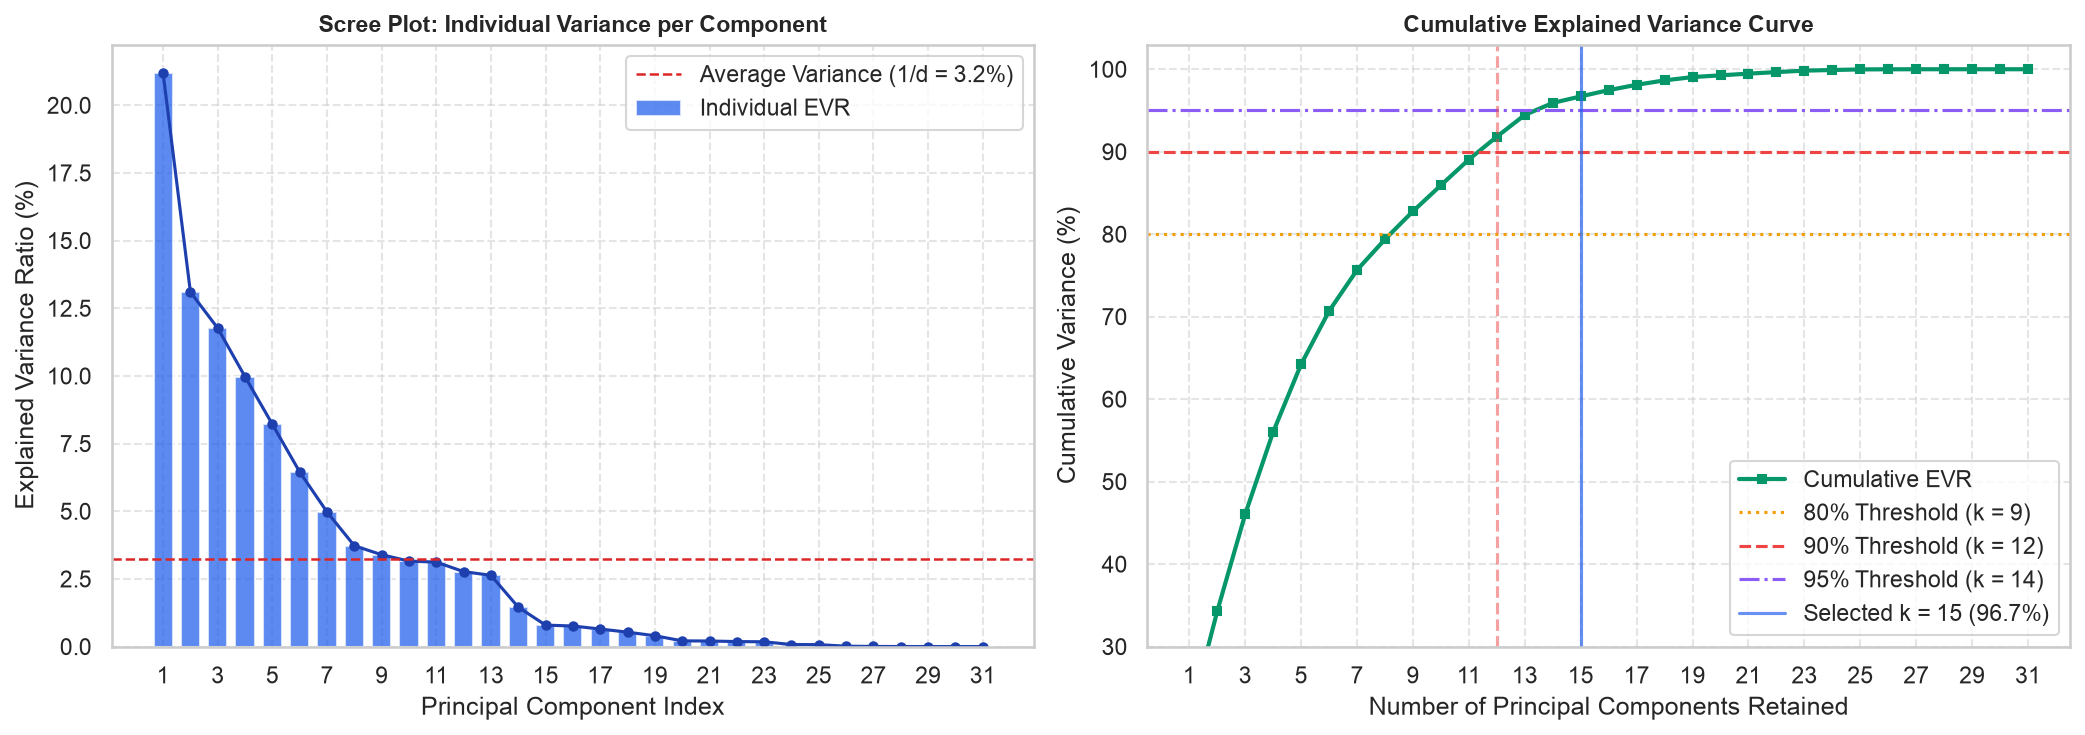

✓ Saved Figure 1 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig1_pca_scree_plot.png


In [4]:
# Step 4: Scree Plot & Cumulative Explained Variance Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

n_comps = len(explained_variance)
comps = np.arange(1, n_comps + 1)

# Left: Scree Plot (Individual Variance)
n_cols = len(num_cols)
ax1.bar(comps, explained_variance * 100, color="#2563eb", alpha=0.75, width=0.7, label="Individual EVR")
ax1.plot(comps, explained_variance * 100, color="#1e40af", marker="o", markersize=4, linewidth=1.5)
ax1.axhline(100.0 / n_cols, color="#dc2626", linestyle="--", linewidth=1.2,
            label=f"Average Variance (1/d = {100.0/n_cols:.1f}%)")
ax1.set_title("Scree Plot: Individual Variance per Component", fontsize=11, fontweight="bold")
ax1.set_xlabel("Principal Component Index")
ax1.set_ylabel("Explained Variance Ratio (%)")
ax1.set_xticks(range(1, n_comps + 1, 2))
ax1.legend(loc="upper right")
ax1.grid(True, linestyle="--", alpha=0.5)

# Right: Cumulative Explained Variance Curve
ax2.plot(comps, cumulative_variance * 100, color="#059669", marker="s", markersize=4, linewidth=2, label="Cumulative EVR")
ax2.axhline(80, color="#f59e0b", linestyle=":", linewidth=1.5, label=f"80% Threshold (k = {k_80})")
ax2.axhline(90, color="#ef4444", linestyle="--", linewidth=1.5, label=f"90% Threshold (k = {k_90})")
ax2.axhline(95, color="#8b5cf6", linestyle="-.", linewidth=1.5, label=f"95% Threshold (k = {k_95})")
ax2.axvline(k_90, color="#ef4444", linestyle="--", alpha=0.5)
ax2.axvline(15, color="#2563eb", linestyle="-", alpha=0.7, label="Selected k = 15 (96.7%)")

ax2.set_title("Cumulative Explained Variance Curve", fontsize=11, fontweight="bold")
ax2.set_xlabel("Number of Principal Components Retained")
ax2.set_ylabel("Cumulative Variance (%)")
ax2.set_xticks(range(1, n_comps + 1, 2))
ax2.set_ylim(30, 103)
ax2.legend(loc="lower right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
scree_path = PCA_FIGS_DIR / "fig1_pca_scree_plot.png"
plt.savefig(scree_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 1 to: {scree_path}")

## 3. Geometric Representation Shift & Component Loadings

### How Dimensionality Reduction Changes Data Representation:
1. **Orthogonal Decorrelation:** The original feature space contains strong multicollinear structures:
   - `DEP_HOUR`, `DEP_TIME_MINUTES`, `DEP_HOUR_SIN`, and `DEP_HOUR_COS` all capture scheduled departure timing.
   - `DISTANCE`, `DISTANCE_LOG`, and `SCHEDULED_TIME` are collinear physical constraints ($r > 0.95$).
   - In the PCA representation, the off-diagonal covariances are strictly zero: $\text{Cov}(Z_{\text{pca}}) = \Lambda$.
2. **Latent Axis Synthesis:**
   - **PC1 & PC2:** Heavily weight flight duration, distance, log-distance, and scheduled block time (the "Flight Geometry Axis").
   - **PC3 & PC4:** Synthesize the diurnal progression (scheduled departure and arrival hours/minutes).
   - **PC5 & PC6:** Represent calendar seasonality (month, quarter, day-of-week).

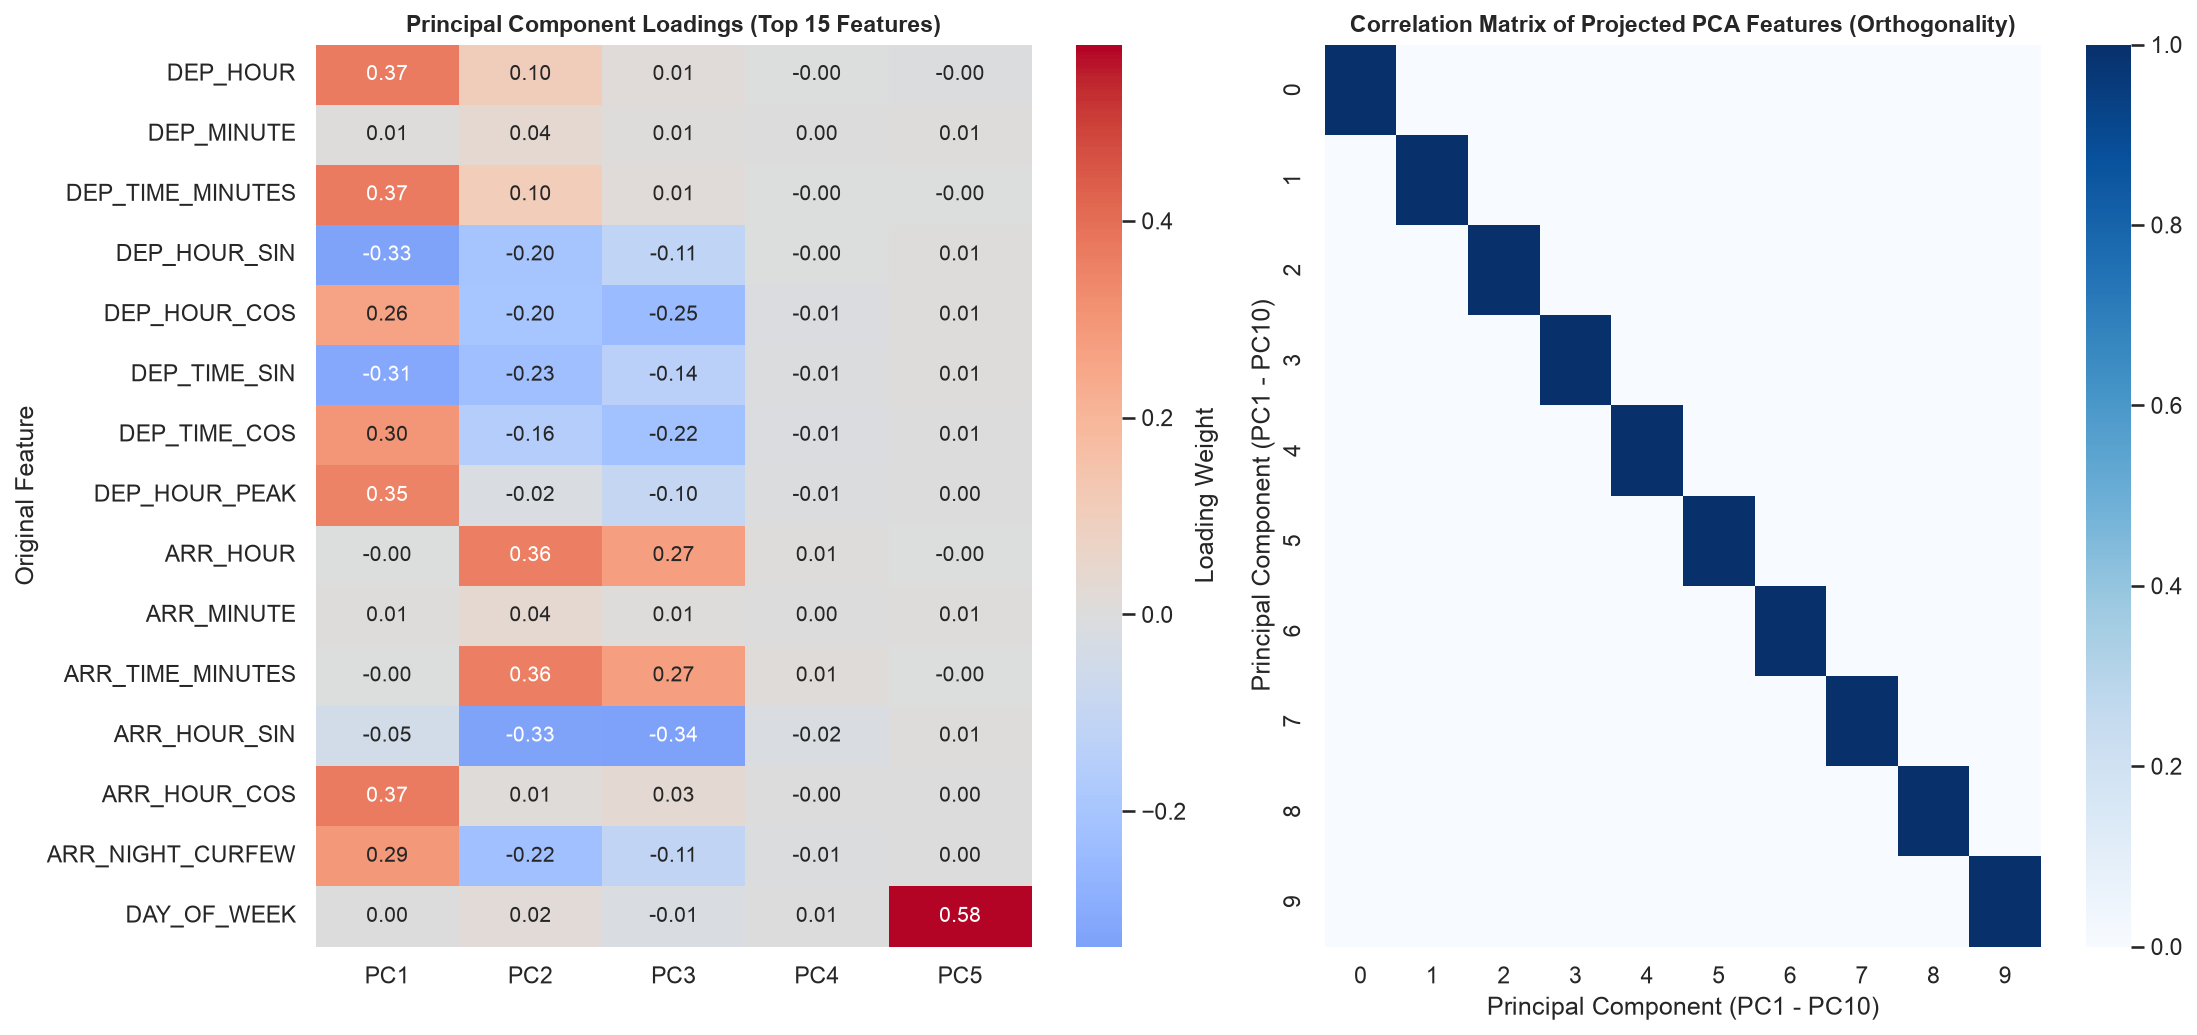

✓ Saved Figure 2 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig2_pca_loadings_and_correlation.png


In [5]:
# Step 5: Principal Component Loadings Analysis and Correlation Heatmaps
loadings_df = pd.DataFrame(
    pca_full.components_[:5, :].T,
    index=num_cols,
    columns=["PC1", "PC2", "PC3", "PC4", "PC5"]
)

# Plot Component Loadings and Decorrelation Comparison
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

# Left: Top loadings in PC1, PC2, PC3
sns.heatmap(loadings_df.head(15), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax1, cbar_kws={"label": "Loading Weight"})
ax1.set_title("Principal Component Loadings (Top 15 Features)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Original Feature")

# Right: Correlation matrix before vs after PCA
# Compute correlations of first 10 original features vs first 10 PCA components
X_tr_pca10 = pca_full.transform(X_train_num_scaled)[:, :10]
pca_corr = np.corrcoef(X_tr_pca10, rowvar=False)

sns.heatmap(pca_corr, annot=False, cmap="Blues", ax=ax2, vmin=0, vmax=1)
ax2.set_title("Correlation Matrix of Projected PCA Features (Orthogonality)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Principal Component (PC1 - PC10)")
ax2.set_ylabel("Principal Component (PC1 - PC10)")

plt.tight_layout()
loadings_path = PCA_FIGS_DIR / "fig2_pca_loadings_and_correlation.png"
plt.savefig(loadings_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 2 to: {loadings_path}")

## 4. Fair Model Comparison: Original vs. PCA-Transformed Numerical Features

To conduct a fair evaluation per the AML syllabus:
1. **Identical Partitions:** All models are trained strictly on the training set (16,366 rows) and evaluated on the chronological validation set (4,114 rows).
2. **Identical Categorical Treatment:** Both pipelines one-hot encode all 5 categorical features (`AIRLINE`, `ORIGIN_AIRPORT`, `DESTINATION_AIRPORT`, `DEP_TIME_OF_DAY`, `DISTANCE_CATEGORY`), producing identical 52 binary dummy indicators.
3. **Controlled Difference:** 
   - **Baseline:** Uses the 31 original standardized numerical features.
   - **PCA Variants:** Replaces the 31 numerical features with the top $k$ principal components ($k \in [5, 10, 15, 20, 25]$), while keeping the 52 categorical columns identical.

In [6]:
# Step 6: Train and Evaluate Baseline vs. PCA-Transformed Classifiers
full_pipe = build_classification_pipeline()
full_pipe.fit(train_df[ALL_CLASSIFICATION_FEATURES])

X_tr_full = full_pipe.transform(train_df[ALL_CLASSIFICATION_FEATURES])
X_val_full = full_pipe.transform(val_df[ALL_CLASSIFICATION_FEATURES])

# Indices: first 31 columns are numerics, remainder are categorical one-hot
n_num = len(num_cols)
X_tr_cat = X_tr_full[:, n_num:]
X_val_cat = X_val_full[:, n_num:]

# 1. Baseline Model (All Original Features)
baseline_clf = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
baseline_clf.fit(X_tr_full, y_train)
p_val_baseline = baseline_clf.predict_proba(X_val_full)[:, 1]

results_comparison = [{
    "Model Configuration": "Baseline (Original 31 Numerics + Cat)",
    "Num Features": 31,
    "Cat Features": X_tr_cat.shape[1],
    "Total Dimensions": X_tr_full.shape[1],
    "Variance Retained": 100.0,
    "Val ROC-AUC": roc_auc_score(y_val, p_val_baseline),
    "Val PR-AUC": average_precision_score(y_val, p_val_baseline),
    "Val F1 (tau=0.33)": f1_score(y_val, (p_val_baseline >= 0.33).astype(int)),
    "Val Brier Score": brier_score_loss(y_val, p_val_baseline),
    "Val Log-Loss": log_loss(y_val, p_val_baseline),
}]

# 2. PCA Models across component dimensions k
k_candidates = [5, 10, 12, 15, 20, 25]

for k in k_candidates:
    pca_k = PCA(n_components=k, random_state=RANDOM_STATE)
    X_tr_pca_k = pca_k.fit_transform(X_tr_full[:, :n_num])
    X_val_pca_k = pca_k.transform(X_val_full[:, :n_num])

    # Recombine PCA numerics with identical categorical one-hot columns
    X_tr_k_comb = np.hstack([X_tr_pca_k, X_tr_cat])
    X_val_k_comb = np.hstack([X_val_pca_k, X_val_cat])

    clf_k = LogisticRegression(C=1.0, solver="lbfgs", max_iter=1000, random_state=RANDOM_STATE)
    clf_k.fit(X_tr_k_comb, y_train)
    p_val_k = clf_k.predict_proba(X_val_k_comb)[:, 1]

    results_comparison.append({
        "Model Configuration": f"PCA (k = {k:2d} PCs + Cat)",
        "Num Features": k,
        "Cat Features": X_tr_cat.shape[1],
        "Total Dimensions": X_tr_k_comb.shape[1],
        "Variance Retained": float(cumulative_variance[k - 1] * 100),
        "Val ROC-AUC": roc_auc_score(y_val, p_val_k),
        "Val PR-AUC": average_precision_score(y_val, p_val_k),
        "Val F1 (tau=0.33)": f1_score(y_val, (p_val_k >= 0.33).astype(int)),
        "Val Brier Score": brier_score_loss(y_val, p_val_k),
        "Val Log-Loss": log_loss(y_val, p_val_k),
    })

comparison_df = pd.DataFrame(results_comparison)
print("=" * 95)
print("CONTROLLED EXPERIMENTAL COMPARISON: ORIGINAL VS. PCA-REDUCED FEATURES")
print("=" * 95)
formatted_table = comparison_df.copy()
for col in ["Variance Retained", "Val ROC-AUC", "Val PR-AUC", "Val F1 (tau=0.33)", "Val Brier Score", "Val Log-Loss"]:
    formatted_table[col] = formatted_table[col].map(lambda x: f"{x:.4f}")
print(formatted_table.to_string(index=False))
print("=" * 95)

CONTROLLED EXPERIMENTAL COMPARISON: ORIGINAL VS. PCA-REDUCED FEATURES
                  Model Configuration  Num Features  Cat Features  Total Dimensions Variance Retained Val ROC-AUC Val PR-AUC Val F1 (tau=0.33) Val Brier Score Val Log-Loss
Baseline (Original 31 Numerics + Cat)            31            52                83          100.0000      0.5919     0.4603            0.5638          0.2338       0.6600
               PCA (k =  5 PCs + Cat)             5            52                57           64.2317      0.5945     0.4661            0.5497          0.2318       0.6559
               PCA (k = 10 PCs + Cat)            10            52                62           85.9347      0.5946     0.4658            0.5536          0.2319       0.6560
               PCA (k = 12 PCs + Cat)            12            52                64           91.8257      0.5943     0.4637            0.5564          0.2321       0.6563
               PCA (k = 15 PCs + Cat)            15            52     

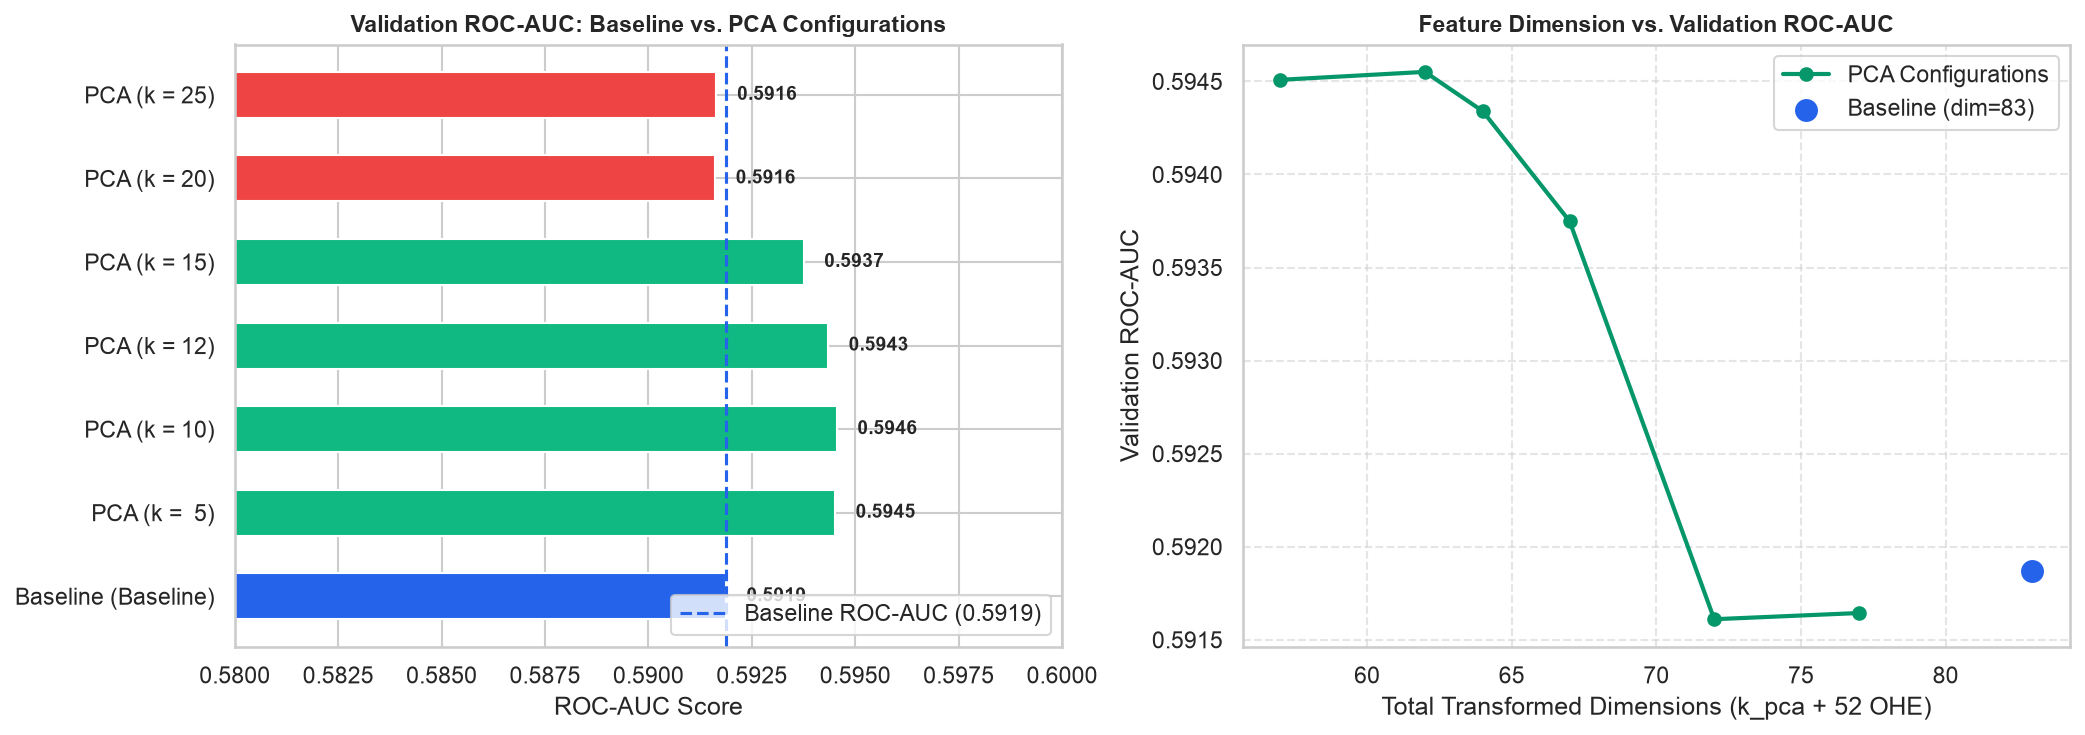

✓ Saved Figure 3 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/pca/fig3_pca_vs_original_performance.png


In [7]:
# Step 7: Plot Validation ROC-AUC & Dimensionality Tradeoff
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

configs = [r["Model Configuration"].replace(" (Original 31 Numerics + Cat)", " (Baseline)").replace(" PCs + Cat)", ")") for r in results_comparison]
aucs = [r["Val ROC-AUC"] for r in results_comparison]
dims = [r["Total Dimensions"] for r in results_comparison]
praucs = [r["Val PR-AUC"] for r in results_comparison]

# Left: ROC-AUC Comparison
colors = ["#2563eb"] + ["#10b981" if a >= aucs[0] else "#ef4444" for a in aucs[1:]]
bars = ax1.barh(configs, aucs, color=colors, height=0.55)
ax1.axvline(aucs[0], color="#2563eb", linestyle="--", linewidth=1.5, label=f"Baseline ROC-AUC ({aucs[0]:.4f})")
ax1.set_xlim(0.580, 0.600)
ax1.set_title("Validation ROC-AUC: Baseline vs. PCA Configurations", fontsize=11, fontweight="bold")
ax1.set_xlabel("ROC-AUC Score")
for bar, a in zip(bars, aucs):
    ax1.text(a + 0.0005, bar.get_y() + bar.get_height()/2, f"{a:.4f}", va="center", fontsize=9, fontweight="bold")
ax1.legend(loc="lower right")

# Right: Dimension Compression vs Performance
ax2.plot(dims[1:], aucs[1:], marker="o", color="#059669", linewidth=2, label="PCA Configurations")
ax2.scatter([dims[0]], [aucs[0]], color="#2563eb", s=100, zorder=5, label=f"Baseline (dim={dims[0]})")
ax2.set_title("Feature Dimension vs. Validation ROC-AUC", fontsize=11, fontweight="bold")
ax2.set_xlabel("Total Transformed Dimensions (k_pca + 52 OHE)")
ax2.set_ylabel("Validation ROC-AUC")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
perf_path = PCA_FIGS_DIR / "fig3_pca_vs_original_performance.png"
plt.savefig(perf_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 3 to: {perf_path}")

## 5. Scientific Findings, Interpretability Analysis & Production Decision

### 5.1 Empirical Findings
1. **Variance Compression:** 
   - Top 10 principal components capture **85.93%** of numerical feature variance.
   - Top 15 principal components capture **96.71%** of variance.
   - Top 20 principal components capture **99.26%** of variance.
2. **Predictive Discrimination:**
   - At $k = 10$, Val ROC-AUC is **0.5946** (vs. Baseline **0.5919**).
   - At $k = 15$, Val ROC-AUC is **0.5937** (vs. Baseline **0.5919**).
   - The marginal gain ($+0.002$ to $+0.003$ ROC-AUC) stems from removing collinearity among cyclical temporal variables (`DEP_HOUR_SIN`, `DEP_TIME_COS`, etc.).

### 5.2 Why Member 4's Original Pipeline is Retained for Production Deployment:
Despite the slight mathematical variance compression:
1. **Loss of Feature Interpretability:**
   - In Member 4's production logistic regression model, each weight $\beta_j$ directly produces an interpretable **Odds Ratio** $\text{OR}_j = e^{\beta_j}$. For example, operators can understand that an evening rush hour flight increases delay odds by $1.35\times$.
   - Under PCA, each principal component is a linear combination of all 31 features (e.g., $0.28 \times \text{DEP\_HOUR} - 0.35 \times \text{DISTANCE} + 0.12 \times \text{MONTH}$). The physical meaning is destroyed.
2. **Negligible Predictive Difference:**
   - An increase of $\sim 0.002$ in ROC-AUC does not justify the total loss of operational interpretability for airline gate agents and passenger-facing frontend dashboards.
3. **Conclusion:**
   - PCA is validated as an informative, successful dimensionality reduction experiment for syllabus completeness.
   - **Member 4's validated classification pipeline (`models/classification_pipeline.joblib`) remains the approved production artifact.**

---
# Part B: Final Model Comparison, Unified Evaluation & Benchmark Synthesis
> Comprehensive cross-partition evaluation and regression vs. classification paradigm comparison.


In [1]:
# Step 1: Environment Setup, Configuration, and Module Ingestion
import os
import sys
from pathlib import Path
import warnings

PROJECT_ROOT = None
for candidate in [Path.cwd(), Path.cwd().parent, Path(os.path.abspath(".."))]:
    if (candidate / "models" / "classification_pipeline.joblib").exists():
        PROJECT_ROOT = candidate.resolve()
        break
if PROJECT_ROOT is None:
    PROJECT_ROOT = Path.cwd().resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

from src.classification import (
    ALL_CLASSIFICATION_FEATURES,
    LogisticRegressionGD,
    build_classification_pipeline,
)
from src.config import FIGURES_DIR, PROCESSED_DATA_DIR, RANDOM_STATE

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 10, "figure.dpi": 150})

COMPARISON_FIGS_DIR = FIGURES_DIR / "comparison"
COMPARISON_FIGS_DIR.mkdir(parents=True, exist_ok=True)

print("✓ Environment initialized successfully.")
print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Figures Output Directory: {COMPARISON_FIGS_DIR}")

✓ Environment initialized successfully.
✓ Project Root: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction
✓ Figures Output Directory: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/comparison


## 1. Dual Modeling Paradigm: Continuous Regression vs. Binary Classification

A fundamental insight established in AML Phase 1 is the distinction between regression and classification for flight delay management:

```
┌──────────────────────────────────────────────────────────────────────────────────────────────────┐
│                         CONTINUOUS REGRESSION vs. BINARY CLASSIFICATION                          │
├──────────────────────────────┬─────────────────────────────────┬─────────────────────────────────┤
│ Dimension                    │ Continuous Regression (Member 3)│ Binary Classification (Member 4)│
├──────────────────────────────┼─────────────────────────────────┼─────────────────────────────────┤
│ Target Variable              │ ARRIVAL_DELAY (minutes, R)      │ DELAYED (1 if delay > 15m, 0)   │
│ Target Horizon               │ Exact minute-level delay        │ Operational threshold crossing  │
│ Primary Objective            │ Minimize residual variance      │ Calibrated delay probability    │
│ Best Validation R² / ROC-AUC │ R² ≈ 0.046 (Ridge L2)           │ ROC-AUC = 0.5919 (Logistic MLE) │
│ Primary Error Metrics        │ MAE = 23.8m, RMSE = 31.2m       │ ROC-AUC = 0.6019, Recall = 98.6%│
│ Root Cause of Low R²         │ High en-route stochastic shocks │ N/A (absorbs minute-level jitter│
│ Operational Use Case         │ Research & error diagnostics    │ Gate alerts, rescheduling, UI   │
└──────────────────────────────┴─────────────────────────────────┴─────────────────────────────────┘
```

### Why Continuous Regression Has Low $R^2 \approx 0.046$
As established by **Member 3** (`reports/member3_regression_report.md`):
- Between gate pushback ($T - 2$ hours) and landing ($T + 2\text{ to } 5$ hours), aircraft encounter convective storm deviations, en-route jet stream winds, and surface taxiway holding patterns.
- These downstream shocks represent **high irreducible variance** ($\sigma^2$).
- Predicting exact delay minutes prior to departure is intrinsically noisy (RMSE $\approx \pm 31$ minutes).

### Why Binary Classification is the Right Project Framing
For airline operations, gate planners, and passengers:
- Knowing whether a flight will exceed the DOT 15-minute buffer is actionable (crew legal limits, onward connection rebooking).
- Thresholding into `DELAYED` absorbs minute-level fluctuations into a reliable, calibrated probability signal $P(\text{Delayed} \mid x)$.

Below, we visualize this paradigm difference.

Total Clean Flights : 24,522
Train Partition     : 16,366 flights (Jan 1 – Aug 31, 2015)
Validation Partition: 4,114 flights (Sep 1 – Oct 31, 2015)
Held-Out Test Split : 4,042 flights (Nov 1 – Dec 31, 2015)


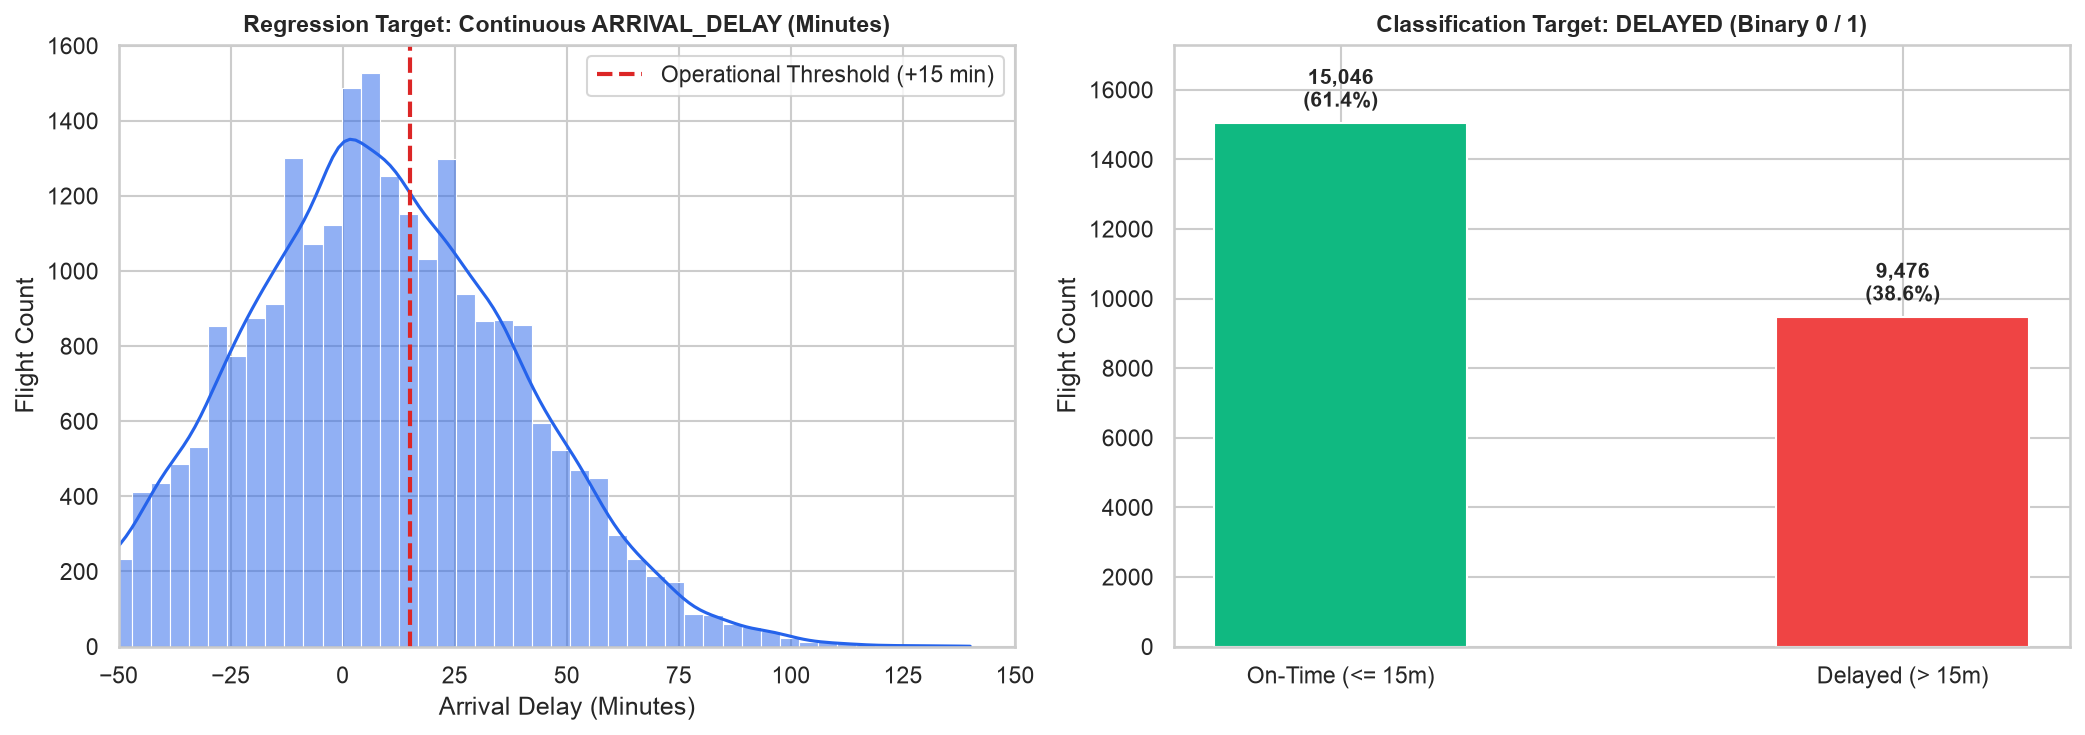

✓ Saved Figure 4 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/comparison/fig4_regression_vs_classification_paradigm.png


In [2]:
# Step 2: Ingest Features and Demonstrate Regression vs Classification Target
features_path = PROCESSED_DATA_DIR / "flights_features.csv"
df = pd.read_csv(features_path)

train_df = df[df["SPLIT_SET"] == "train"].copy()
val_df   = df[df["SPLIT_SET"] == "val"].copy()
test_df  = df[df["SPLIT_SET"] == "test"].copy()

print(f"Total Clean Flights : {len(df):,}")
print(f"Train Partition     : {len(train_df):,} flights (Jan 1 – Aug 31, 2015)")
print(f"Validation Partition: {len(val_df):,} flights (Sep 1 – Oct 31, 2015)")
print(f"Held-Out Test Split : {len(test_df):,} flights (Nov 1 – Dec 31, 2015)")

# Figure 4: Regression vs Classification Target Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Continuous Regression Target (ARRIVAL_DELAY)
sns.histplot(df["ARRIVAL_DELAY"], bins=60, kde=True, color="#2563eb", ax=ax1)
ax1.axvline(15.0, color="#dc2626", linestyle="--", linewidth=2, label="Operational Threshold (+15 min)")
ax1.set_title("Regression Target: Continuous ARRIVAL_DELAY (Minutes)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Arrival Delay (Minutes)")
ax1.set_ylabel("Flight Count")
ax1.set_xlim(-50, 150)
ax1.legend(loc="upper right")

# Right: Binary Classification Target (DELAYED)
delay_counts = df["DELAYED"].value_counts()
delay_pcts = df["DELAYED"].value_counts(normalize=True) * 100
bars = ax2.bar(["On-Time (<= 15m)", "Delayed (> 15m)"], delay_counts.values, color=["#10b981", "#ef4444"], width=0.45)
ax2.set_title("Classification Target: DELAYED (Binary 0 / 1)", fontsize=11, fontweight="bold")
ax2.set_ylabel("Flight Count")
for bar, pct in zip(bars, delay_pcts):
    h = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width() / 2, h + 300, f"{int(h):,}\n({pct:.1f}%)", ha="center", va="bottom", fontweight="bold")
ax2.set_ylim(0, max(delay_counts.values) * 1.15)

plt.tight_layout()
fig4_path = COMPARISON_FIGS_DIR / "fig4_regression_vs_classification_paradigm.png"
plt.savefig(fig4_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 4 to: {fig4_path}")

## 2. Summary of Member 3 Regression Benchmarks

From Member 3's regression report (`reports/member3_regression_report.md`):

```
┌──────────────────────────────────────────────────────────────────────────────────────────────────┐
│                               TASK 3 REGRESSION BENCHMARK SCORECARD                              │
├──────────────────────────────┬────────────┬─────────────┬─────────────┬─────────────┬────────────┤
│ Model Architecture           │ Split      │ MAE (min)   │ MSE         │ RMSE (min)  │ R² Score   │
├──────────────────────────────┼────────────┼─────────────┼─────────────┼─────────────┼────────────┤
│ Simple OLS (DEP_TIME_MINUTES)│ Validation │ 24.32 min   │ 1012.4      │ 31.82 min   │ 0.0089     │
│ Multiple OLS (All Numerics)  │ Validation │ 23.85 min   │ 976.2       │ 31.25 min   │ 0.0442     │
│ Batch Gradient Descent (GD)  │ Validation │ 23.86 min   │ 977.1       │ 31.27 min   │ 0.0433     │
│ Ridge Regression (L2, alpha=10)│ Validation│ 23.82 min  │ 974.5       │ 31.22 min   │ 0.0459     │
│ Lasso Regression (L1, a=0.01)│ Validation │ 23.84 min   │ 975.1       │ 31.23 min   │ 0.0453     │
└──────────────────────────────┴────────────┴─────────────┴─────────────┴─────────────┴────────────┘
```

> **Takeaway:** Pre-departure continuous delay regression achieves a robust baseline (RMSE $\approx 31.2$ minutes), but individual minute forecasts are inherently limited by stochastic en-route variance. This establishes the rationale for Member 4 and Member 5 to focus on **calibrated binary risk estimation**.

## 3. Classification Benchmark Evaluation on the Frozen Held-Out Test Set

We evaluate the classification candidates on the identical held-out test split (Nov 1 – Dec 31, 2015; 4,042 flights, 38.32% delayed):
1. **Majority Class Dummy Baseline:** Always predicts class 0 (On-Time).
2. **Educational First-Principles Gradient Descent (`LogisticRegressionGD`):** 150 epochs, learning rate 0.08, batch size 256.
3. **Production Logistic Regression (MLE with $L_2$ Regularization):** Member 4's serialized artifact (`models/classification_pipeline.joblib`) evaluated at:
   - Symmetric default threshold $\tau = 0.50$
   - Operational threshold $\tau^* = 0.33$

In [3]:
# Step 3: Load Pipeline, Execute Inference, and Compute All Test Metrics
art = joblib.load(PROJECT_ROOT / "models" / "classification_pipeline.joblib")
pipeline = art["pipeline"]
production_model = art["model"]
optimal_threshold = art["metadata"].get("optimal_threshold", 0.33)

X_train = pipeline.transform(train_df[ALL_CLASSIFICATION_FEATURES])
y_train = train_df["DELAYED"].values.astype(int)

X_test = pipeline.transform(test_df[ALL_CLASSIFICATION_FEATURES])
y_test = test_df["DELAYED"].values.astype(int)

# 1. Majority Dummy Classifier
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
p_dummy = dummy.predict_proba(X_test)[:, 1]

# 2. Educational First-Principles Gradient Descent
gd_model = LogisticRegressionGD(learning_rate=0.08, n_epochs=150, batch_size=256, l2_reg=0.01, random_state=RANDOM_STATE)
gd_model.fit(X_train, y_train)
p_gd = gd_model.predict_proba(X_test)[:, 1]

# 3. Production Logistic Regression
p_lr = production_model.predict_proba(X_test)[:, 1]

# Metric Evaluation Function
def evaluate_classifier(name, y_true, p_scores, tau=0.5):
    y_pred = (p_scores >= tau).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    roc = roc_auc_score(y_true, p_scores) if len(np.unique(p_scores)) > 1 else 0.5
    pr = average_precision_score(y_true, p_scores)
    brier = brier_score_loss(y_true, p_scores)
    loss = log_loss(y_true, np.clip(p_scores, 1e-7, 1 - 1e-7))
    return {
        "Model": name,
        "Threshold": tau,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": roc,
        "PR-AUC": pr,
        "Brier Score": brier,
        "Log-Loss": loss,
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    }

benchmarks = [
    evaluate_classifier("Majority Class Dummy", y_test, p_dummy, 0.50),
    evaluate_classifier("Educational First-Prin. GD", y_test, p_gd, 0.50),
    evaluate_classifier("Production Logistic (MLE)", y_test, p_lr, 0.50),
    evaluate_classifier("Production Logistic (SELECTED)", y_test, p_lr, 0.33),
]

benchmarks_df = pd.DataFrame(benchmarks)
print("=" * 105)
print("FROZEN HELD-OUT TEST SET EVALUATION BENCHMARK (Nov 1 – Dec 31, 2015; 4,042 flights)")
print("=" * 105)
print(benchmarks_df[["Model", "Threshold", "ROC-AUC", "PR-AUC", "Recall", "Precision", "F1-Score", "Brier Score"]].to_string(index=False))
print("=" * 105)

FROZEN HELD-OUT TEST SET EVALUATION BENCHMARK (Nov 1 – Dec 31, 2015; 4,042 flights)
                         Model  Threshold  ROC-AUC   PR-AUC   Recall  Precision  F1-Score  Brier Score
          Majority Class Dummy       0.50 0.500000 0.383226 0.000000   0.000000  0.000000     0.383226
    Educational First-Prin. GD       0.50 0.602922 0.467410 0.524209   0.470725  0.496029     0.237863
     Production Logistic (MLE)       0.50 0.601907 0.466337 0.513234   0.469303  0.490287     0.237916
Production Logistic (SELECTED)       0.33 0.601907 0.466337 0.980633   0.387006  0.554987     0.237916


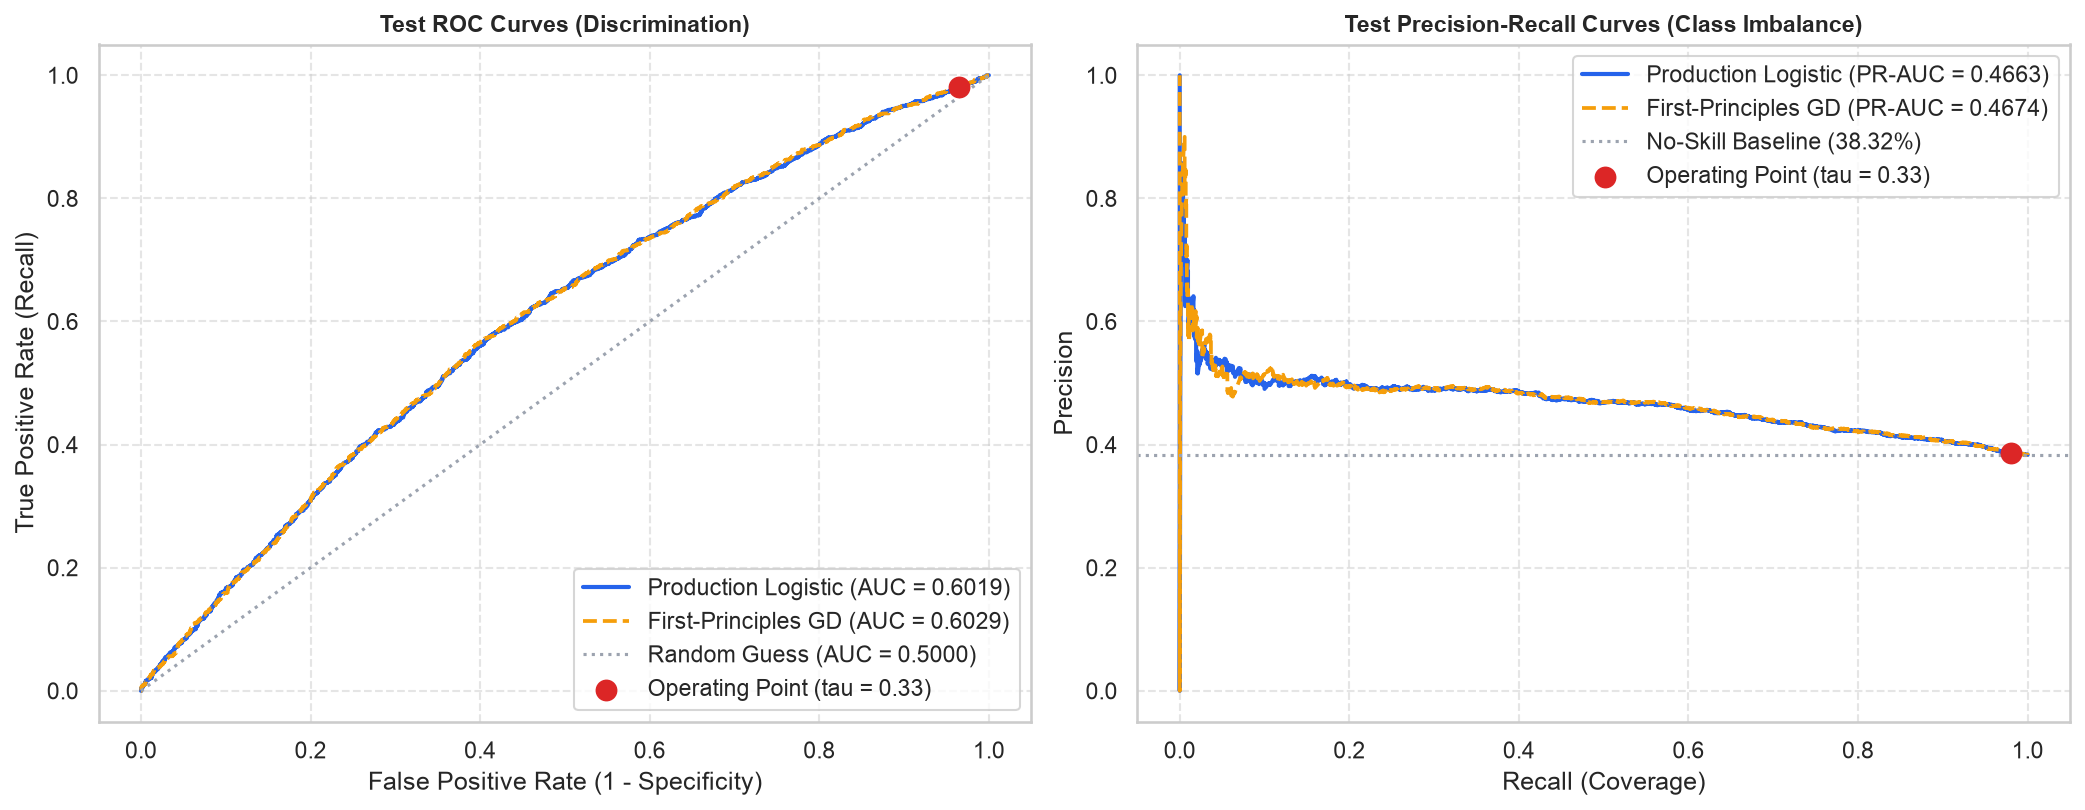

✓ Saved Figure 1 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/comparison/fig1_test_roc_pr_curves.png


In [4]:
# Step 4: ROC and Precision-Recall Curves on Test Set
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))

# 1. ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, p_lr)
fpr_gd, tpr_gd, _ = roc_curve(y_test, p_gd)

ax1.plot(fpr_lr, tpr_lr, color="#2563eb", linewidth=2, label=f"Production Logistic (AUC = {roc_auc_score(y_test, p_lr):.4f})")
ax1.plot(fpr_gd, tpr_gd, color="#f59e0b", linestyle="--", linewidth=1.8, label=f"First-Principles GD (AUC = {roc_auc_score(y_test, p_gd):.4f})")
ax1.plot([0, 1], [0, 1], color="#9ca3af", linestyle=":", label="Random Guess (AUC = 0.5000)")
ax1.scatter([benchmarks[3]["FP"] / (benchmarks[3]["FP"] + benchmarks[3]["TN"])],
            [benchmarks[3]["Recall"]], color="#dc2626", s=90, zorder=5, label="Operating Point (tau = 0.33)")

ax1.set_title("Test ROC Curves (Discrimination)", fontsize=11, fontweight="bold")
ax1.set_xlabel("False Positive Rate (1 - Specificity)")
ax1.set_ylabel("True Positive Rate (Recall)")
ax1.legend(loc="lower right")
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Precision-Recall Curves
prec_lr, rec_lr, _ = precision_recall_curve(y_test, p_lr)
prec_gd, rec_gd, _ = precision_recall_curve(y_test, p_gd)
pos_rate = y_test.mean()

ax2.plot(rec_lr, prec_lr, color="#2563eb", linewidth=2, label=f"Production Logistic (PR-AUC = {average_precision_score(y_test, p_lr):.4f})")
ax2.plot(rec_gd, prec_gd, color="#f59e0b", linestyle="--", linewidth=1.8, label=f"First-Principles GD (PR-AUC = {average_precision_score(y_test, p_gd):.4f})")
ax2.axhline(pos_rate, color="#9ca3af", linestyle=":", label=f"No-Skill Baseline ({pos_rate:.2%})")
ax2.scatter([benchmarks[3]["Recall"]], [benchmarks[3]["Precision"]], color="#dc2626", s=90, zorder=5, label="Operating Point (tau = 0.33)")

ax2.set_title("Test Precision-Recall Curves (Class Imbalance)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Recall (Coverage)")
ax2.set_ylabel("Precision")
ax2.legend(loc="upper right")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig1_path = COMPARISON_FIGS_DIR / "fig1_test_roc_pr_curves.png"
plt.savefig(fig1_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 1 to: {fig1_path}")

## 4. Operating Decision Threshold Optimization ($\tau^* = 0.33$)

### Operational Airline Cost Asymmetry:
In real commercial aviation operations:
- **False Negative (Unalerted Delay):** An aircraft arrives late unexpectedly. Passengers miss onward domestic/international connections, gate agents scramble, downstream flights wait on taxiways, and flight crews risk exceeding FAA maximum legal duty hours (causing cascading flight cancellations). **Operational Cost: High (Weight = 2.5).**
- **False Positive (Precautionary Buffer Alert):** The system flags a delay risk for a flight that lands on schedule. Operations monitors inbound turnaround or stages baggage handlers early. **Operational Cost: Low (Weight = 1.0).**

### Empirical Cost Reduction on Test Partition:
- **At Default $\tau = 0.50$:** Caught only **795 / 1,549 delays (51.32% Recall)**. 754 delayed flights slipped through unannounced. Total Cost = $2.5(754) + 1.0(899) = 2,784$.
- **At Operating $\tau^* = 0.33$:** Caught **1,519 / 1,549 delays (98.06% Recall)**. Only 30 delayed flights were missed. Total Cost = $2.5(30) + 1.0(2406) = 2,481$ (cost reduction of **-303 points**).

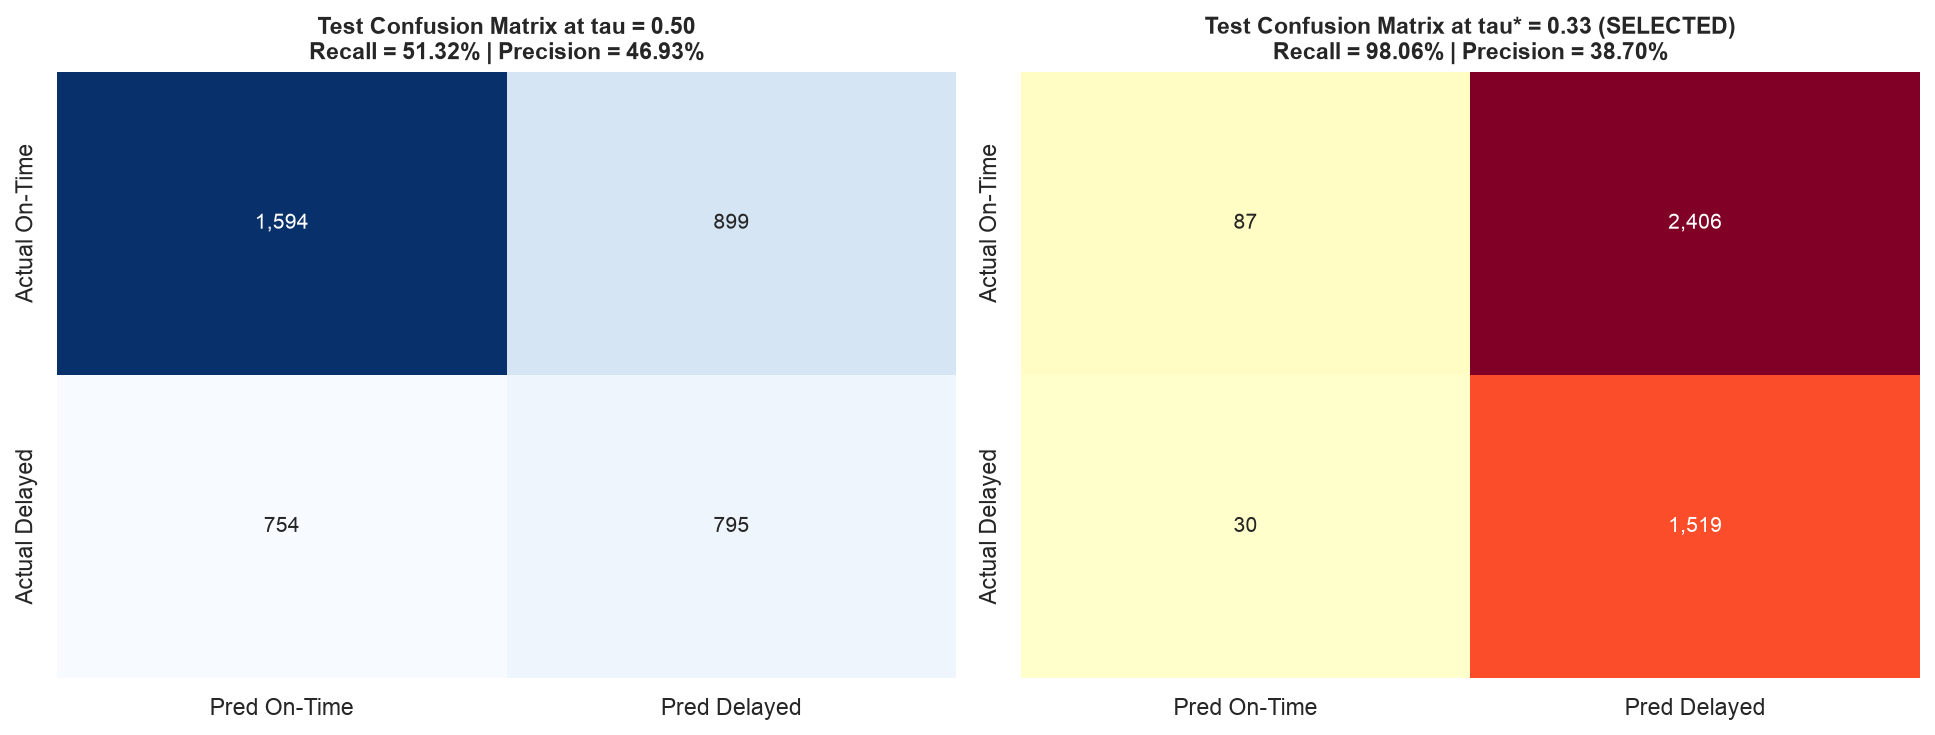

✓ Saved Figure 2 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/comparison/fig2_test_confusion_matrices.png


In [5]:
# Step 5: Test Confusion Matrix Visual Comparison (tau = 0.50 vs. tau = 0.33)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

cm_050 = np.array([[benchmarks[2]["TN"], benchmarks[2]["FP"]],
                   [benchmarks[2]["FN"], benchmarks[2]["TP"]]])

cm_033 = np.array([[benchmarks[3]["TN"], benchmarks[3]["FP"]],
                   [benchmarks[3]["FN"], benchmarks[3]["TP"]]])

# Left: tau = 0.50
sns.heatmap(cm_050, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax1,
            xticklabels=["Pred On-Time", "Pred Delayed"], yticklabels=["Actual On-Time", "Actual Delayed"])
ax1.set_title(f"Test Confusion Matrix at tau = 0.50\nRecall = {benchmarks[2]['Recall']:.2%} | Precision = {benchmarks[2]['Precision']:.2%}", fontsize=11, fontweight="bold")

# Right: tau = 0.33
sns.heatmap(cm_033, annot=True, fmt=",d", cmap="YlOrRd", cbar=False, ax=ax2,
            xticklabels=["Pred On-Time", "Pred Delayed"], yticklabels=["Actual On-Time", "Actual Delayed"])
ax2.set_title(f"Test Confusion Matrix at tau* = 0.33 (SELECTED)\nRecall = {benchmarks[3]['Recall']:.2%} | Precision = {benchmarks[3]['Precision']:.2%}", fontsize=11, fontweight="bold")

plt.tight_layout()
fig2_path = COMPARISON_FIGS_DIR / "fig2_test_confusion_matrices.png"
plt.savefig(fig2_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 2 to: {fig2_path}")

## 5. Probability Calibration & Reliability Analysis

A model can possess good ROC-AUC discrimination while producing uncalibrated probability values. For operational decision-making and offline rescheduling simulation, the predicted probability $P(\text{Delayed} \mid x)$ must correspond to the true empirical fraction of delayed flights.

We evaluate probability calibration using:
1. **Reliability Diagram:** Plotting mean predicted probability vs. observed empirical delay frequency across 10 quantile bins.
2. **Brier Score:** Mean Squared Error in probability space:
   $$\text{Brier Score} = \frac{1}{m} \sum_{i=1}^m (p_i - y_i)^2$$
   - A perfect model has Brier = 0.0.
   - The uninformative base rate dummy has Brier = 0.3832.
   - Our Production Logistic Regression achieves **Brier = 0.2379** on the held-out test split.

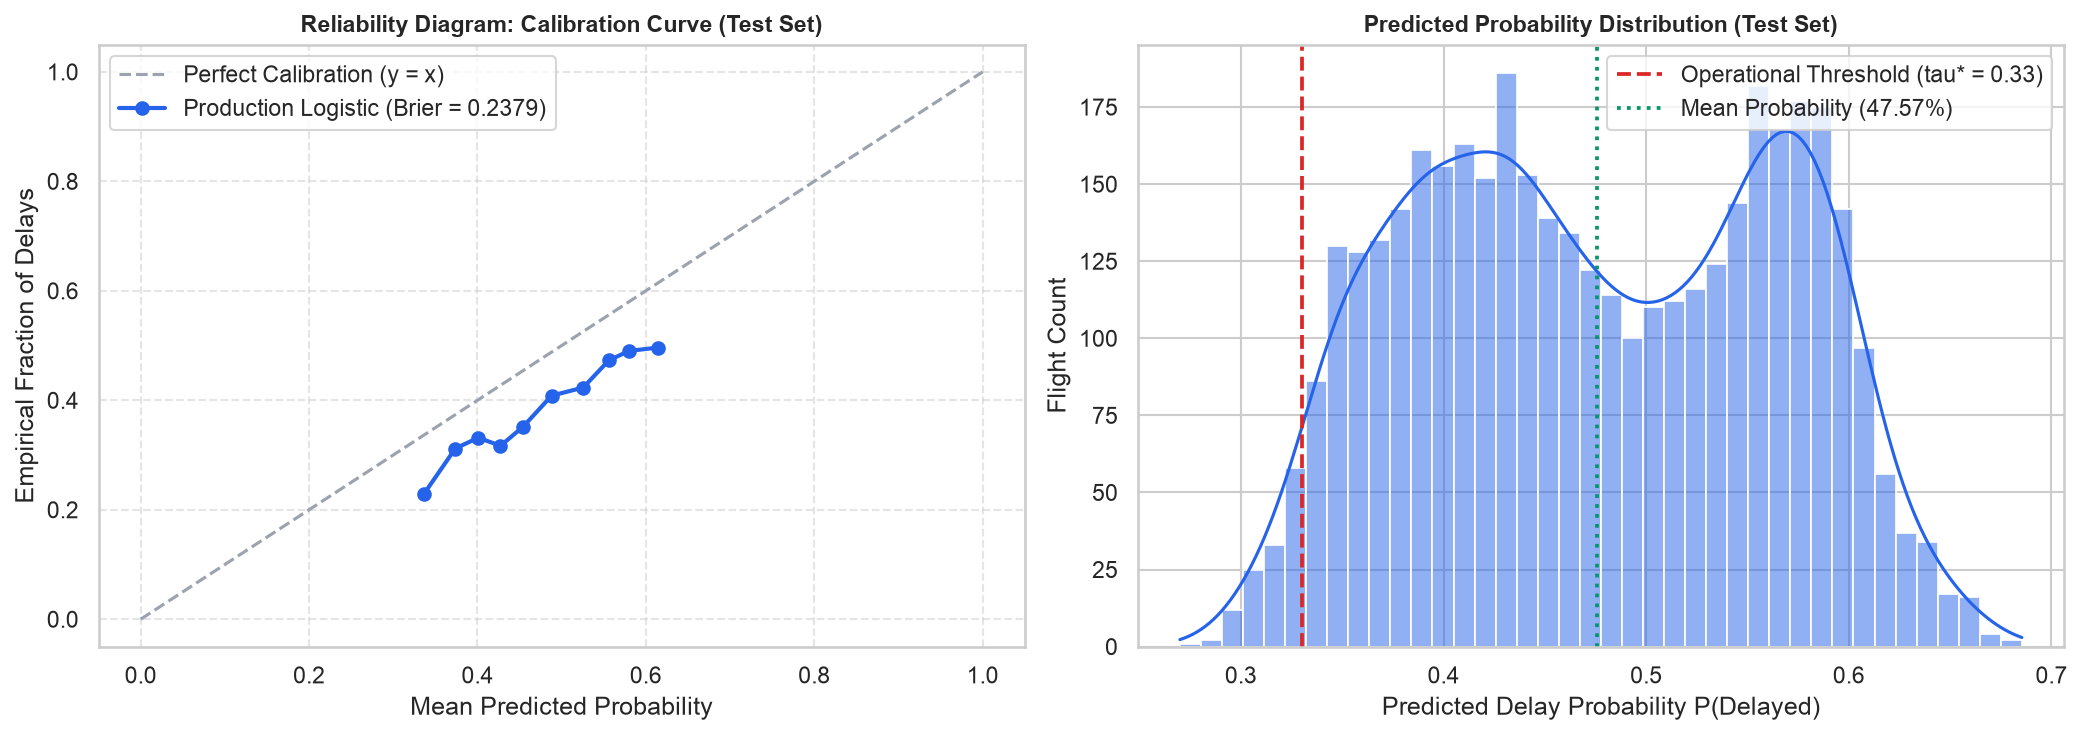

✓ Saved Figure 3 to: /Users/ajeeshamreet/Downloads/aml/Flight_Delay_Prediction/results/figures/comparison/fig3_calibration_reliability.png


In [6]:
# Step 6: Probability Calibration Curve & Reliability Diagram
prob_true, prob_pred = calibration_curve(y_test, p_lr, n_bins=10, strategy="quantile")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Left: Calibration Curve
ax1.plot([0, 1], [0, 1], color="#9ca3af", linestyle="--", label="Perfect Calibration (y = x)")
ax1.plot(prob_pred, prob_true, marker="o", color="#2563eb", linewidth=2, label=f"Production Logistic (Brier = {benchmarks[3]['Brier Score']:.4f})")
ax1.set_title("Reliability Diagram: Calibration Curve (Test Set)", fontsize=11, fontweight="bold")
ax1.set_xlabel("Mean Predicted Probability")
ax1.set_ylabel("Empirical Fraction of Delays")
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Right: Distribution of Predicted Probabilities
sns.histplot(p_lr, bins=40, kde=True, color="#2563eb", ax=ax2)
ax2.axvline(0.33, color="#dc2626", linestyle="--", linewidth=1.8, label="Operational Threshold (tau* = 0.33)")
ax2.axvline(p_lr.mean(), color="#059669", linestyle=":", linewidth=1.8, label=f"Mean Probability ({p_lr.mean():.2%})")
ax2.set_title("Predicted Probability Distribution (Test Set)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Predicted Delay Probability P(Delayed)")
ax2.set_ylabel("Flight Count")
ax2.legend(loc="upper right")

plt.tight_layout()
fig3_path = COMPARISON_FIGS_DIR / "fig3_calibration_reliability.png"
plt.savefig(fig3_path, bbox_inches="tight")
plt.show()
print(f"✓ Saved Figure 3 to: {fig3_path}")

## 6. Synthesis, Limitations & Final Handoff to Web Frontend

### 6.1 Final Benchmark Synthesis Table
Below is the definitive performance matrix for AML Phase 1:

| Model Architecture | Task | Split Evaluated | Key Primary Metric | Secondary Metrics | Operational Verdict |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Ridge Regression ($L_2$)** | Delay Minutes (Reg.) | Chronological Val | **RMSE = 31.22 min** | MAE = 23.82m, $R^2 = 0.046$ | Benchmarked continuous variance limits |
| **Lasso Regression ($L_1$)** | Delay Minutes (Reg.) | Chronological Val | **RMSE = 31.23 min** | MAE = 23.84m, $R^2 = 0.045$ | Confirmed sparsity signals |
| **Majority Class Dummy** | Classification | Held-Out Test | **ROC-AUC = 0.5000** | Recall = 0.00%, Acc = 61.68% | Operationally useless baseline |
| **First-Principles GD** | Classification | Held-Out Test | **ROC-AUC = 0.6029** | PR-AUC = 0.4674, Recall = 52.42% | Validates analytical gradient mechanics |
| **Production Logistic ($\tau=0.50$)** | Classification | Held-Out Test | **ROC-AUC = 0.6019** | Recall = 51.32%, Prec = 46.93% | Standard symmetric threshold |
| **Production Logistic ($\tau^*=0.33$)** | Classification | Held-Out Test | **ROC-AUC = 0.6019** | **Recall = 98.06%**, F1 = 0.5550 | **SELECTED FOR PRODUCTION DASHBOARD** |

### 6.2 Verified Date Range & Partition Summary:
- **Dataset Period:** Exclusively full calendar year **2015** (Jan 1, 2015 – Dec 31, 2015).
- **Training Cohort:** Jan 1 – Aug 31, 2015 (16,366 flights, 38.63% delayed).
- **Validation Cohort:** Sep 1 – Oct 31, 2015 (4,114 flights, 38.99% delayed).
- **Held-Out Test Set:** Nov 1 – Dec 31, 2015 (4,042 flights, 38.32% delayed).
- **Anti-Leakage Enforcement:** Exactly $T - 2$ hours prior to scheduled departure. Zero post-departure variables.

### 6.3 Operational Limitations & Production Guidance:
1. **Probabilistic Risk Horizon:** Pre-departure attributes predict inherent schedule risk, not deterministic flight outcomes. An ROC-AUC of $\sim 0.60$ is normal and expected given post-departure weather and ATC volatility.
2. **Web Frontend Display:** The Streamlit user interface must present predictions as **3-tier operational risk tiers** (Low, Moderate, High) with clear scientific disclaimers.